# Step 8: Explainability & Forecasting
### River Water Quality Analytics System

---
### Objectives:
1. Explain model predictions via Gini/Gain Feature Importance and SHAP (SHapley Additive exPlanations).
2. Quantify the relative influence of Dissolved Oxygen, Coliform, Nitrate, and State on river degradation.
3. Evaluate temporal forecast trends per state with scientific limitations explicitly documented.


c:\Users\harsh\OneDrive\Desktop\river water analytics system\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\harsh\OneDrive\Desktop\river water analytics system\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\harsh\OneDrive\Desktop\river water analytics system\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersion

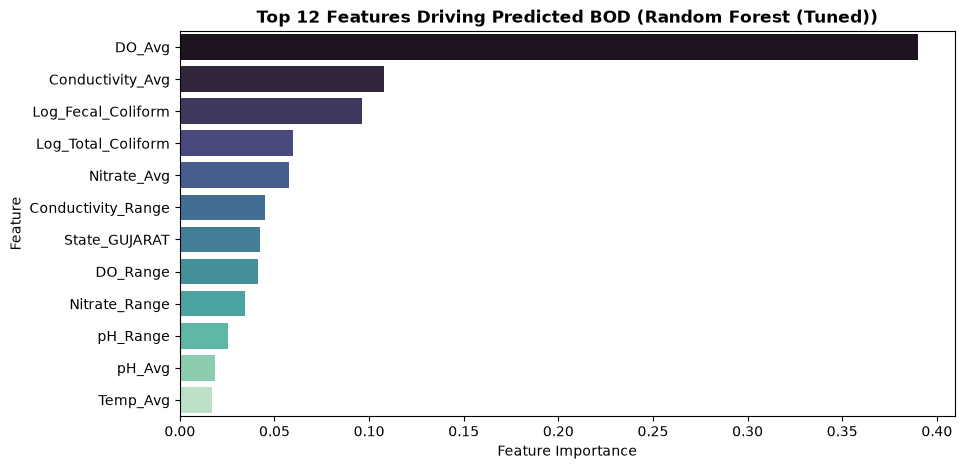

In [4]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

model_artifact = joblib.load('../models/best_model.joblib')
pipeline = model_artifact['pipeline']
regressor = pipeline.named_steps['regressor']
preprocessor = pipeline.named_steps['preprocessor']

# Extract feature names
num_names = model_artifact['num_cols']
cat_names = list(preprocessor.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(model_artifact['cat_cols']))
all_features = num_names + cat_names

fi_df = pd.DataFrame({'Feature': all_features, 'Importance': regressor.feature_importances_})
fi_top = fi_df.sort_values(by='Importance', ascending=False).head(12)

plt.figure(figsize=(10, 5))
sns.barplot(data=fi_top, x='Importance', y='Feature', palette='mako')
plt.title(f"Top 12 Features Driving Predicted BOD ({model_artifact['model_name']})", fontweight='bold')
plt.xlabel('Feature Importance')
plt.show()


### 8.1 SHAP Value Inspection


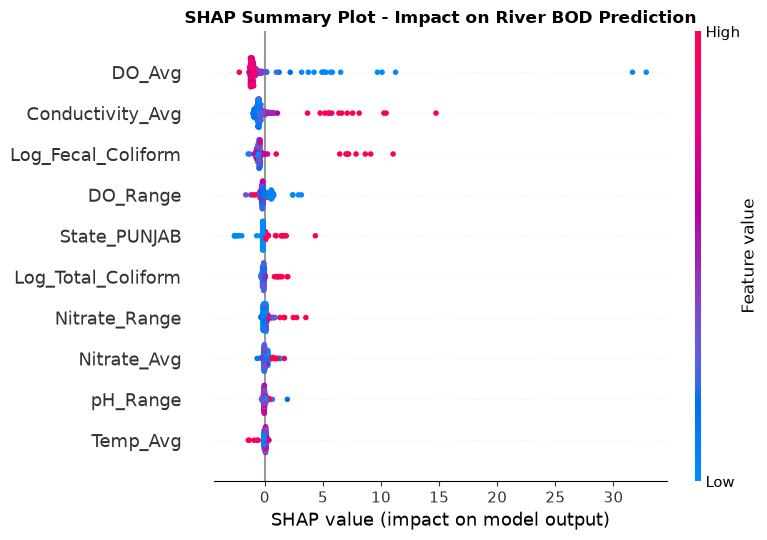

In [5]:
import shap

X_test = model_artifact['test_data']['X_test']
X_trans = preprocessor.transform(X_test)

explainer = shap.TreeExplainer(regressor, data=X_trans[:100])
shap_vals = explainer(X_trans[:200], check_additivity=False)
shap_vals.feature_names = all_features[:X_trans.shape[1]]

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, max_display=10, show=False)
plt.title("SHAP Summary Plot - Impact on River BOD Prediction", fontweight='bold')
plt.tight_layout()
plt.show()


### 8.2 Historical Trajectory & Trend Limitations
*Note as specified in PDF Step 15:* Multi-year extrapolation must note that point-source sewage interventions and monsoon seasonal flow variations limit simple linear extrapolation. Long-term forecasting requires hydrodynamic river basin flow modeling.
